นาย อัญญาฤทธิ์ จ๊ะราจา 670510777 โฟล์ค 0824777935

# DeepLabV3 (torchvision)

- DeepLabV3 is designed for semantic segmentation at multiple scales, trained on a subset of COCO using the 20 Pascal VOC categories (plus background).
- It uses ResNet50 as a backbone.

ถอดตามภาพตัวอย่างสำหรับ Google Colab รันเซลล์จากบนลงล่าง ใช้ URL รูปแมวตามภาพ หรือแก้ `folder_path` และ `IMG_PATH` เพื่อใช้รูปของคุณเอง ชื่อโฟลเดอร์และไฟล์ที่ถูกปิดไว้ในภาพใช้ placeholder แทน

คงการ resize, normalization และสีตามตัวอย่าง ปรับ `pretrained=True` เป็น `weights` และใช้ `Image.Resampling` สำหรับ Pillow ไฟล์นี้ยังไม่มีผลรันโมเดลจริง

อ้างอิง weights: [torchvision DeepLabV3 ResNet50](https://docs.pytorch.org/vision/2.0/models/generated/torchvision.models.segmentation.deeplabv3_resnet50.html)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
folder_path = '/content/drive/MyDrive/Colab Notebooks/ImgProc/Images/'

In [ ]:
%pip -q install torch torchvision pillow matplotlib numpy requests

In [ ]:
import torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as T
from torchvision import models
import requests, io, os

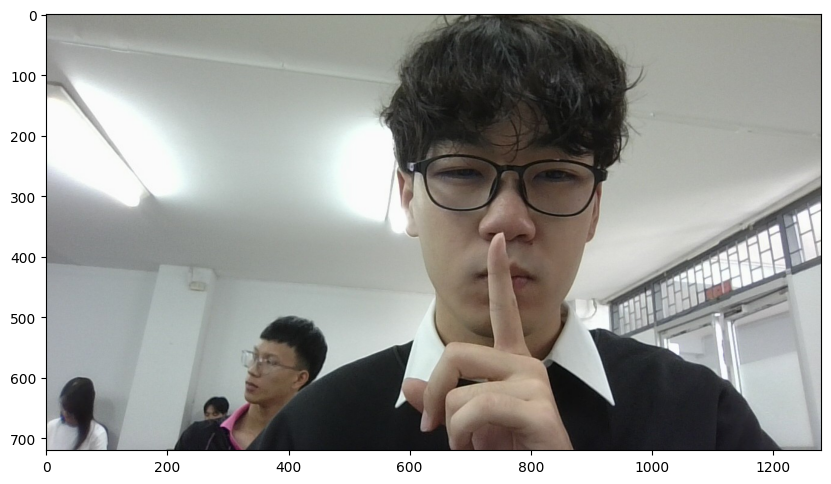

In [ ]:
IMG_PATH = "sui.jpg"

img_pil = Image.open(os.path.join(folder_path, IMG_PATH))
plt.figure(figsize=(10,10))
plt.imshow(img_pil)
plt.show()

def resize_short_side(pil_img, short_side=640, max_side=1024):
    w, h = pil_img.size
    s = min(w, h)
    scale = short_side / s
    new_w, new_h = int(w * scale), int(h * scale)
    # clamp the long side
    if max(new_w, new_h) > max_side:
        scale = max_side / max(new_w, new_h)
        new_w, new_h = int(new_w * scale), int(new_h * scale)
    return pil_img.resize((max(1, new_w), max(1, new_h)), Image.Resampling.BILINEAR)

img_pil = resize_short_side(img_pil, short_side=640, max_side=1024) # speed knob

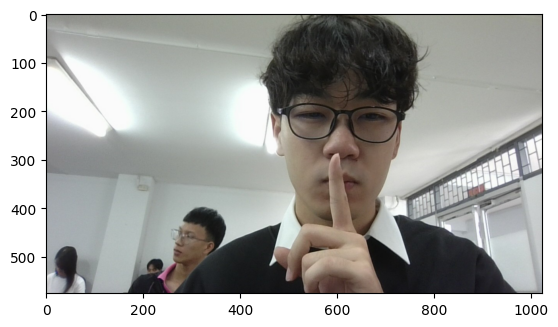

In [ ]:
plt.imshow(img_pil)
plt.show()

In [ ]:
# ===== Preprocess =====
# DeepLab expects ImageNet normalization
preprocess = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
                # Define mean and standard deviation for each channel RGB.
])
img_tensor = preprocess(img_pil).unsqueeze(0)
                # Adds a batch dimension: [N, C, H, W] = [1, 3, H, W].

print(img_tensor.shape)

torch.Size([1, 3, 576, 1024])


In [ ]:
# ===== Load model =====
model = models.segmentation.deeplabv3_resnet50(
    weights=models.segmentation.DeepLabV3_ResNet50_Weights.COCO_WITH_VOC_LABELS_V1
).eval()

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:02<00:00, 75.2MB/s]


In [ ]:
# ===== Inference =====
with torch.no_grad():
    out = model(img_tensor)["out"]         # [1, C, H, W]
    pred = out.softmax(dim=1).argmax(dim=1)[0] # [H, W] class map

In [ ]:
# ===== Colorize & overlay =====
def colorize_mask(mask):
    np.random.seed(0) # stable colors per run
    n_classes = int(mask.max().item()) + 1
    palette = np.random.randint(0, 255, size=(n_classes, 3), dtype=np.uint8)
    color = palette[mask.cpu().numpy()]
    return Image.fromarray(color)

mask_img = colorize_mask(pred)

# Blend on top of the original
overlay = Image.blend(img_pil, mask_img.resize(img_pil.size, Image.Resampling.NEAREST),
                      alpha=0.5)

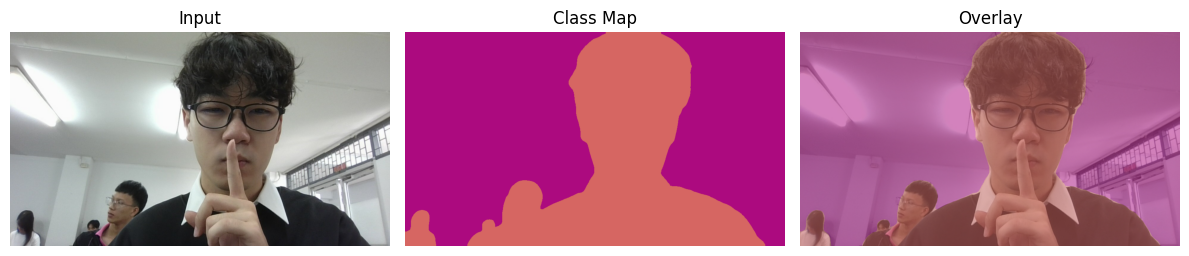

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(img_pil); plt.axis("off"); plt.title("Input")
plt.subplot(1,3,2); plt.imshow(mask_img); plt.axis("off"); plt.title("Class Map")
plt.subplot(1,3,3); plt.imshow(overlay); plt.axis("off"); plt.title("Overlay")
plt.tight_layout(); plt.show()